# DAWN document history — BA 9130
Run the cells to load `data/dawn_document_history_9130_detail.csv` into `df` and inspect it. Requires pandas. Codes and identifiers are loaded as strings to preserve leading zeros; dates and the two numeric amount columns are then converted.

In [34]:
from pathlib import Path
import pandas as pd
from IPython.display import display

# Locate the data from either the project root or the script directory.
relative_path = Path('data') / 'dawn_document_history_9130_detail.csv'
csv_path = next((folder / relative_path for folder in [Path.cwd(), *Path.cwd().parents]
                 if (folder / relative_path).is_file()), None)
if csv_path is None:
    raise FileNotFoundError(f'Could not find {relative_path}. Start the notebook inside the dawn_Data project.')

df = pd.read_csv(csv_path, dtype='string', encoding='utf-8-sig')
df['source_transaction_date'] = pd.to_datetime(df['source_transaction_date'], errors='raise')
for column in ['source_transaction_amount', 'detail_amount']:
    df[column] = pd.to_numeric(df[column], errors='raise')

print(f'Loaded {len(df):,} rows and {len(df.columns)} columns from {csv_path.name}')
with pd.option_context('display.max_columns', None):
    display(df.head(10))

Loaded 220,842 rows and 29 columns from dawn_document_history_9130_detail.csv


,Doc Number,BA Number,GL Number,source_transaction_date,source_transaction_amount,source_description,source_type,source_fy,trans_code,trans_agency,trans_number,AcctType,Event Type,PostingCD,Fund,Dept/Act/SubAct,Appr,Reporting,BS/Obj/Rev,Sub,Task,Function,RptCat,Ref Doc/Line,Line #/Desc,Comments/Invoice,Amount,detail_amount,source_url
0,CR 050 00001002339,9130,42,2011-05-16,4520.0,APPROPRIATIONS,<NA>,2025,CR,050,00001002339,31,<NA>,<NA>,261,053-0000,108500,<NA>,4203,<NA>,<NA>,<NA>,<NA>,<NA>,REFUND-WASHOE CO SCHOOL,VMILAZZO,"-$4,520.00",-4520.0,http://dawn12.state.nv.us:7778/pls/prodsw/prc_...
1,CR 050 00001002339,9130,42,2011-05-16,4520.0,APPROPRIATIONS,<NA>,2025,CR,050,00001002339,01,<NA>,<NA>,261,053-0000,<NA>,<NA>,1000,<NA>,<NA>,<NA>,<NA>,<NA>,REFUND-WASHOE CO SCHOOL,VMILAZZO,"$4,520.00",4520.0,http://dawn12.state.nv.us:7778/pls/prodsw/prc_...
2,CR 050 0654385A,9130,3061,2003-06-24,-193734.1,INSURANCE PREMIUM TAX,MAJOR,2003,CR,050,0654385A,01,<NA>,<NA>,101,130-0000,<NA>,<NA>,1000,<NA>,<NA>,<NA>,<NA>,<NA>,01 REVERSE CREDIT KEYING ERROR,JBAKER,"-$193,734.10",-193734.1,http://dawn12.state.nv.us:7778/pls/prodsw/prc_...
3,CR 050 0654385A,9130,3061,2003-06-24,-193734.1,INSURANCE PREMIUM TAX,MAJOR,2003,CR,050,0654385A,31,<NA>,<NA>,101,130-0000,913000,<NA>,3061,<NA>,<NA>,<NA>,<NA>,<NA>,01 REVERSE CREDIT KEYING ERROR,JBAKER,"$193,734.10",193734.1,http://dawn12.state.nv.us:7778/pls/prodsw/prc_...
4,CR 050 12333.66A,9130,3031,2005-10-07,-12333.66,LIVE ENTERTAINMENT TAX,MAJOR,2006,CR,050,12333.66A,01,<NA>,<NA>,101,130-0000,<NA>,<NA>,1000,<NA>,<NA>,<NA>,<NA>,<NA>,01 DUP DOC # 6179282,JBAKER,"-$12,333.66",-12333.66,http://dawn12.state.nv.us:7778/pls/prodsw/prc_...
5,CR 050 12333.66A,9130,3031,2005-10-07,-12333.66,LIVE ENTERTAINMENT TAX,MAJOR,2006,CR,050,12333.66A,31,<NA>,<NA>,101,130-0000,913000,<NA>,3031,<NA>,<NA>,<NA>,<NA>,<NA>,01 DUP DOC # 6179282,JBAKER,"$12,333.66",12333.66,http://dawn12.state.nv.us:7778/pls/prodsw/prc_...
6,CR 050 13031106A,9130,3061,2003-11-20,-8187.13,INSURANCE PREMIUM TAX,MAJOR,2004,CR,050,13031106A,01,<NA>,<NA>,101,130-0000,<NA>,<NA>,1000,<NA>,<NA>,<NA>,<NA>,<NA>,01 LIBERTY NTL LIFE # 33030590,JAB,"-$8,187.13",-8187.13,http://dawn12.state.nv.us:7778/pls/prodsw/prc_...
7,CR 050 13031106A,9130,3061,2003-11-20,-8187.13,INSURANCE PREMIUM TAX,MAJOR,2004,CR,050,13031106A,31,<NA>,<NA>,101,130-0000,913000,<NA>,3061,<NA>,<NA>,<NA>,<NA>,<NA>,01 LIBERTY NTL LIFE # 33030590,JAB,"$8,187.13",8187.13,http://dawn12.state.nv.us:7778/pls/prodsw/prc_...
8,CR 050 13031106C,9130,3061,2003-12-10,8187.13,INSURANCE PREMIUM TAX,MAJOR,2004,CR,050,13031106C,31,<NA>,<NA>,101,130-0000,913000,<NA>,3061,<NA>,<NA>,<NA>,<NA>,<NA>,01 REVERSE DEBIT KEYING ERROR,JAB,"-$8,187.13",-8187.13,http://dawn12.state.nv.us:7778/pls/prodsw/prc_...
9,CR 050 13031106C,9130,3061,2003-12-10,8187.13,INSURANCE PREMIUM TAX,MAJOR,2004,CR,050,13031106C,01,<NA>,<NA>,101,130-0000,<NA>,<NA>,1000,<NA>,<NA>,<NA>,<NA>,<NA>,01 REVERSE DEBIT KEYING ERROR,JAB,"$8,187.13",8187.13,http://dawn12.state.nv.us:7778/pls/prodsw/prc_...


In [35]:
# Column types and missing values.
display(pd.DataFrame({'dtype': df.dtypes.astype(str), 'missing_values': df.isna().sum()}))

,dtype,missing_values
Doc Number,string,0
BA Number,string,0
GL Number,string,0
source_transaction_date,datetime64[us],0
source_transaction_amount,Float64,0
source_description,string,0
source_type,string,581
source_fy,string,0
trans_code,string,0
trans_agency,string,0


In [36]:
# GL 3069 transactions with calendar month and year.
df_3069 = df.loc[df['GL Number'].astype('string').str.strip().eq('3069')].copy()
dates = pd.to_datetime(df_3069['source_transaction_date'], errors='raise')
df_3069['month'] = dates.dt.month.astype('Int64')
df_3069['year'] = dates.dt.year.astype('Int64')

print(f'GL 3069: {len(df_3069):,} rows')
display(df_3069)

GL 3069: 343 rows


,Doc Number,BA Number,GL Number,source_transaction_date,source_transaction_amount,source_description,source_type,source_fy,trans_code,trans_agency,...,Function,RptCat,Ref Doc/Line,Line #/Desc,Comments/Invoice,Amount,detail_amount,source_url,month,year
197179,JV 060 DE0004367,9130,3069,2004-06-17,54743206.47,MODIFIED BUSINESS TAX,MAJOR,2004,JV,060,...,<NA>,<NA>,<NA>,MBT TO GF,<NA>,"-$54,743,206.47",-54743206.47,http://dawn12.state.nv.us:7778/pls/prodsw/prc_...,6,2004
197180,JV 060 DE0004367,9130,3069,2004-06-17,54743206.47,MODIFIED BUSINESS TAX,MAJOR,2004,JV,060,...,<NA>,<NA>,<NA>,DIST 3/04,<NA>,"$54,743,206.47",54743206.47,http://dawn12.state.nv.us:7778/pls/prodsw/prc_...,6,2004
197921,JV 060 DE0035384,9130,3069,2004-03-22,52100528.18,MODIFIED BUSINESS TAX,MAJOR,2004,JV,060,...,<NA>,<NA>,<NA>,MBT TO GEN'L FUND,L KNACK,"-$52,100,528.18",-52100528.18,http://dawn12.state.nv.us:7778/pls/prodsw/prc_...,3,2004
197922,JV 060 DE0035384,9130,3069,2004-03-22,52100528.18,MODIFIED BUSINESS TAX,MAJOR,2004,JV,060,...,<NA>,<NA>,<NA>,DISTRIB 12/03 QTR,L KNACK,"$52,100,528.18",52100528.18,http://dawn12.state.nv.us:7778/pls/prodsw/prc_...,3,2004
206541,JV 130 10000009676,9130,3069,2004-08-25,54805754.71,MODIFIED BUSINESS TAX,MAJOR,2004,JV,130,...,<NA>,<NA>,<NA>,<NA>,shudder,"-$54,805,754.71",-54805754.71,http://dawn12.state.nv.us:7778/pls/prodsw/prc_...,8,2004
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
219604,JVD 130 MBT2603,9130,3069,2026-05-18,232392973.78,MODIFIED BUSINESS TAX,MAJOR,2026,JVD,130,...,<NA>,<NA>,<NA>,4 03/26 MBT TO GF,<NA>,"-$232,392,973.78",-232392973.78,http://dawn12.state.nv.us:7778/pls/prodsw/prc_...,5,2026
219605,JVD 130 MBT2604,9130,3069,2026-08-19,221976540.07,MODIFIED BUSINESS TAX,MAJOR,2026,JVD,130,...,<NA>,<NA>,<NA>,1 06/26 MBT -FI MYNT,<NA>,"$10,419,271.68",10419271.68,http://dawn12.state.nv.us:7778/pls/prodsw/prc_...,8,2026
219606,JVD 130 MBT2604,9130,3069,2026-08-19,221976540.07,MODIFIED BUSINESS TAX,MAJOR,2026,JVD,130,...,<NA>,<NA>,<NA>,2 06/26 MBT -GB MYNT,<NA>,"$207,130,856.13",207130856.13,http://dawn12.state.nv.us:7778/pls/prodsw/prc_...,8,2026
219607,JVD 130 MBT2604,9130,3069,2026-08-19,221976540.07,MODIFIED BUSINESS TAX,MAJOR,2026,JVD,130,...,<NA>,<NA>,<NA>,3 06/26 MBT -MI MYNT,<NA>,"$4,426,412.26",4426412.26,http://dawn12.state.nv.us:7778/pls/prodsw/prc_...,8,2026


In [37]:
# Selected GL 3069 detail columns in the requested order.
revenue_table = df_3069[[
    'BA Number', 'GL Number', 'source_description', 'source_fy',
    'Line #/Desc', 'detail_amount', 'month', 'year', 'BS/Obj/Rev'
]].copy()

display(revenue_table)


,BA Number,GL Number,source_description,source_fy,Line #/Desc,detail_amount,month,year,BS/Obj/Rev
197179,9130,3069,MODIFIED BUSINESS TAX,2004,MBT TO GF,-54743206.47,6,2004,3069
197180,9130,3069,MODIFIED BUSINESS TAX,2004,DIST 3/04,54743206.47,6,2004,9622
197921,9130,3069,MODIFIED BUSINESS TAX,2004,MBT TO GEN'L FUND,-52100528.18,3,2004,3069
197922,9130,3069,MODIFIED BUSINESS TAX,2004,DISTRIB 12/03 QTR,52100528.18,3,2004,9622
206541,9130,3069,MODIFIED BUSINESS TAX,2004,<NA>,-54805754.71,8,2004,3069
...,...,...,...,...,...,...,...,...,...
219604,9130,3069,MODIFIED BUSINESS TAX,2026,4 03/26 MBT TO GF,-232392973.78,5,2026,3069
219605,9130,3069,MODIFIED BUSINESS TAX,2026,1 06/26 MBT -FI MYNT,10419271.68,8,2026,9611
219606,9130,3069,MODIFIED BUSINESS TAX,2026,2 06/26 MBT -GB MYNT,207130856.13,8,2026,9611
219607,9130,3069,MODIFIED BUSINESS TAX,2026,3 06/26 MBT -MI MYNT,4426412.26,8,2026,9611


In [38]:
# Keep the requested accounting codes and MBT TO descriptions.
filtered_revenue_table = revenue_table.loc[
    revenue_table['BS/Obj/Rev'].astype('string').str.strip().isin(['3069', '9611'])
].copy()

# Normalize MBT_TO_GF and mixed case; discard text before MBT TO
# and any numeric period suffix (e.g. MBT TO GF 1ST QTR 2013).
descriptions = (
    filtered_revenue_table['Line #/Desc'].astype('string')
    .str.replace('_', ' ', regex=False)
    .str.replace(r'\s+', ' ', regex=True)
    .str.upper()
)
filtered_revenue_table['Line #/Desc'] = (
    descriptions.str.extract(r'\b(MBT TO\s+[^\d]+)', expand=False).str.strip()
)
filtered_revenue_table = filtered_revenue_table.dropna(subset=['Line #/Desc']).copy()

print(f'Filtered rows: {len(filtered_revenue_table):,}')
display(filtered_revenue_table)


Filtered rows: 98


,BA Number,GL Number,source_description,source_fy,Line #/Desc,detail_amount,month,year,BS/Obj/Rev
197179,9130,3069,MODIFIED BUSINESS TAX,2004,MBT TO GF,-54743206.47,6,2004,3069
197921,9130,3069,MODIFIED BUSINESS TAX,2004,MBT TO GEN'L FUND,-52100528.18,3,2004,3069
207471,9130,3069,MODIFIED BUSINESS TAX,2006,MBT TO GENERAL,-64929781.11,8,2006,3069
207563,9130,3069,MODIFIED BUSINESS TAX,2007,MBT TO GF,-69135987.59,11,2006,3069
207691,9130,3069,MODIFIED BUSINESS TAX,2007,MBT TO GF,-74788585.85,4,2007,3069
...,...,...,...,...,...,...,...,...,...
219575,9130,3069,MODIFIED BUSINESS TAX,2026,MBT TO GF,-165824694.06,11,2025,3069
219581,9130,3069,MODIFIED BUSINESS TAX,2026,MBT TO GF,-165588074.02,5,2026,3069
219600,9130,3069,MODIFIED BUSINESS TAX,2026,MBT TO GF,-190764670.77,2,2026,3069
219604,9130,3069,MODIFIED BUSINESS TAX,2026,MBT TO GF,-232392973.78,5,2026,3069


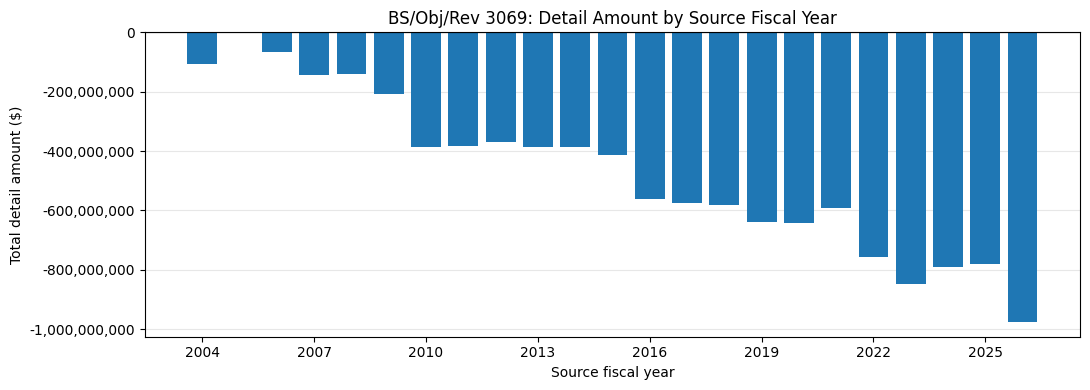

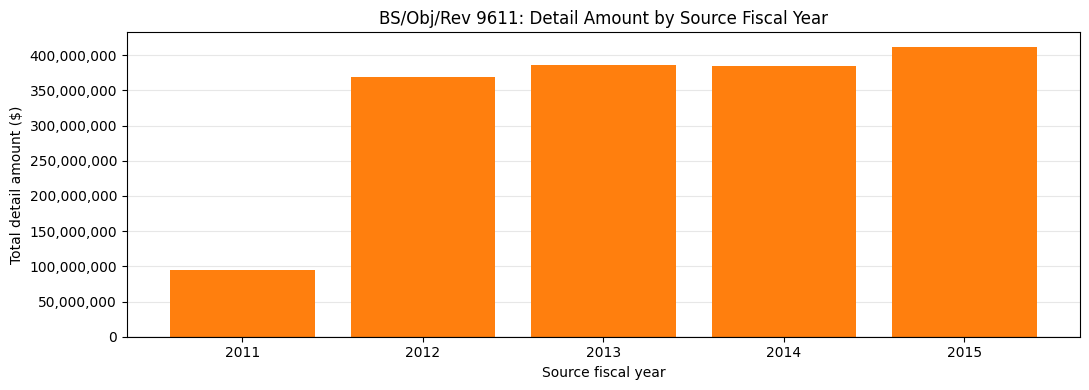

In [39]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator

# Sum signed detail amounts within each accounting code and source fiscal year.
plot_data = filtered_revenue_table.copy()
plot_data['source_fy'] = pd.to_numeric(plot_data['source_fy'], errors='raise').astype('Int64')
plot_data['detail_amount'] = pd.to_numeric(plot_data['detail_amount'], errors='raise')
fy_totals = (
    plot_data.groupby(['BS/Obj/Rev', 'source_fy'], as_index=False)['detail_amount']
    .sum(min_count=1)
    .sort_values(['BS/Obj/Rev', 'source_fy'])
)

for code, color in [('3069', 'tab:blue'), ('9611', 'tab:orange')]:
    series = fy_totals.loc[fy_totals['BS/Obj/Rev'].eq(code)]
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.bar(series['source_fy'].astype(int), series['detail_amount'].astype(float), color=color)
    ax.set_title(f'BS/Obj/Rev {code}: Detail Amount by Source Fiscal Year')
    ax.set_xlabel('Source fiscal year')
    ax.set_ylabel('Total detail amount ($)')
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value:,.0f}'))
    ax.axhline(0, color='black', linewidth=0.8)
    ax.grid(axis='y', alpha=0.3)
    ax.set_axisbelow(True)
    fig.tight_layout()
    plt.show()


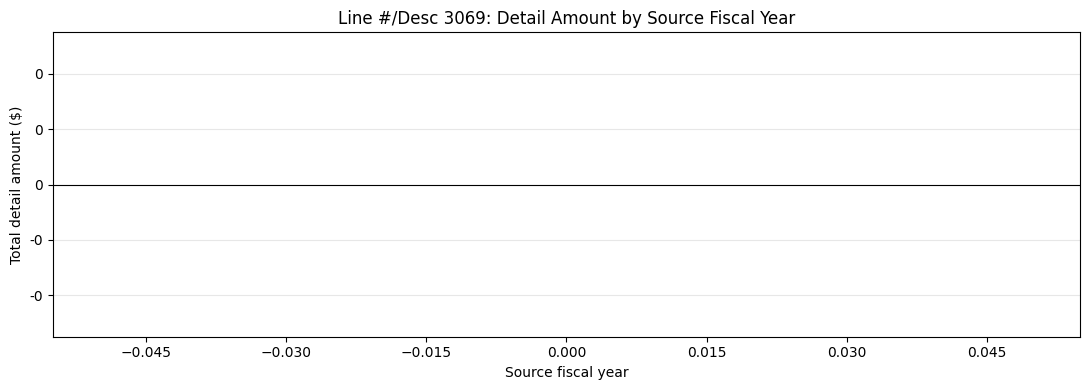

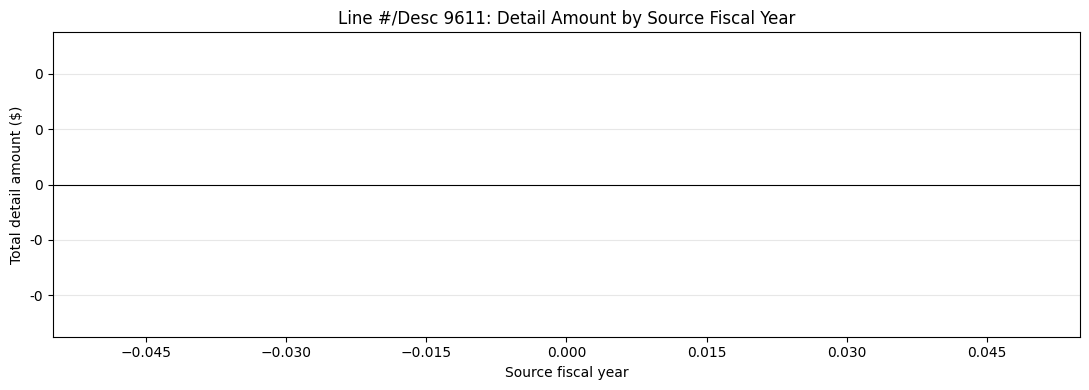

In [40]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator

# Sum signed detail amounts within each accounting code and source fiscal year.
plot_data = filtered_revenue_table.copy()
plot_data['source_fy'] = pd.to_numeric(plot_data['source_fy'], errors='raise').astype('Int64')
plot_data['detail_amount'] = pd.to_numeric(plot_data['detail_amount'], errors='raise')
fy_totals = (
    plot_data.groupby(['Line #/Desc', 'source_fy'], as_index=False)['detail_amount']
    .sum(min_count=1)
    .sort_values(['Line #/Desc', 'source_fy'])
)

for code, color in [('3069', 'tab:blue'), ('9611', 'tab:orange')]:
    series = fy_totals.loc[fy_totals['Line #/Desc'].eq(code)]
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.bar(series['source_fy'].astype(int), series['detail_amount'].astype(float), color=color)
    ax.set_title(f'Line #/Desc {code}: Detail Amount by Source Fiscal Year')
    ax.set_xlabel('Source fiscal year')
    ax.set_ylabel('Total detail amount ($)')
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value:,.0f}'))
    ax.axhline(0, color='black', linewidth=0.8)
    ax.grid(axis='y', alpha=0.3)
    ax.set_axisbelow(True)
    fig.tight_layout()
    plt.show()


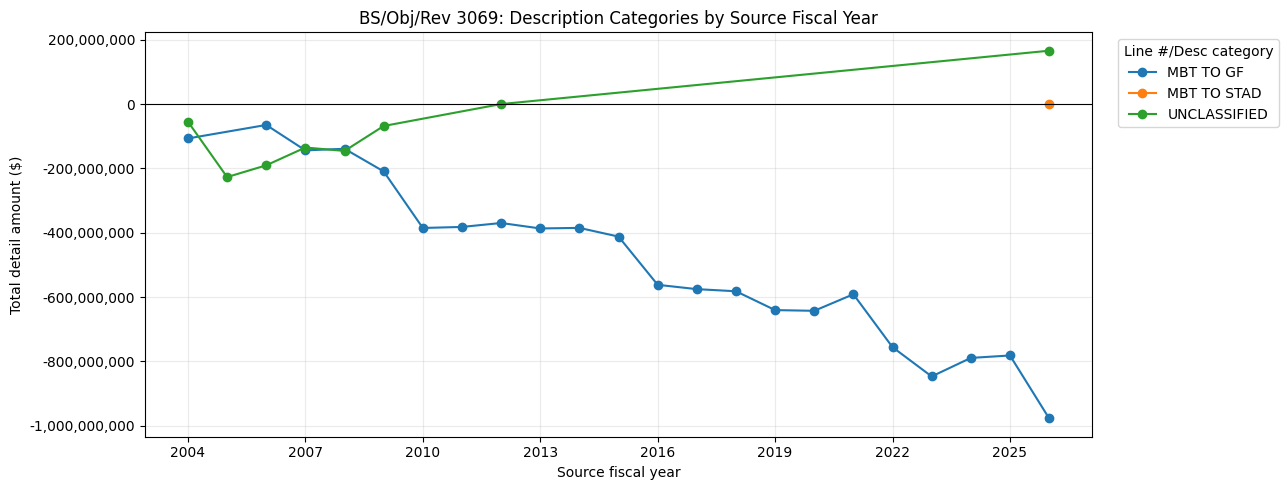

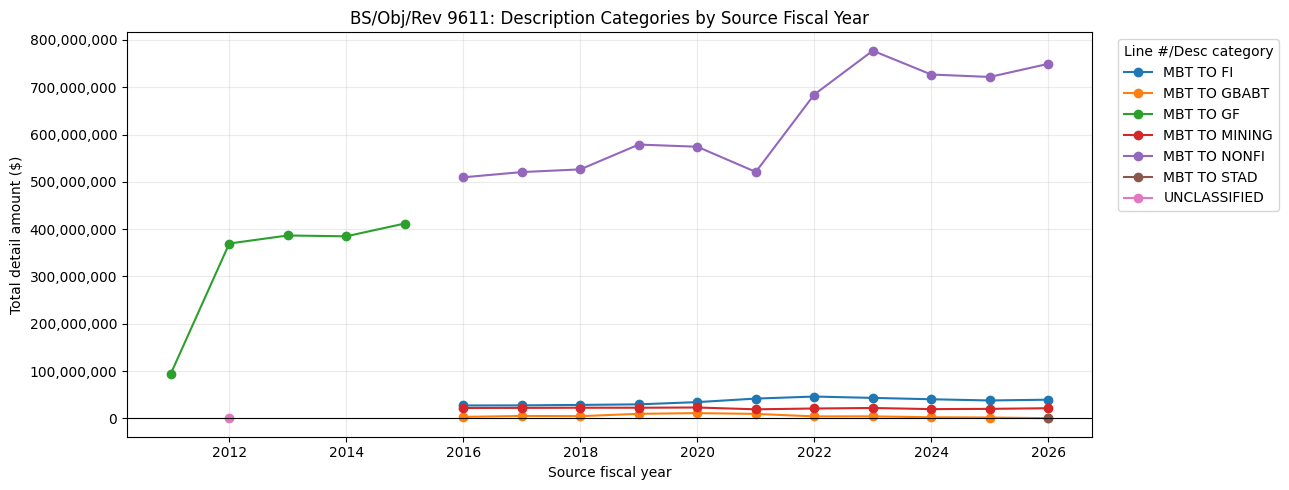

Descriptions included under UNCLASSIFIED:


Line #/Desc
<NA>                         10
CORR 12/11 MBT DISTRIBUTE     2
6/05 mbt distribution         1
To Distribute 3rd QTR Mod     1
Modified BT to GF             1
DIST 3RD QTR MBT- GEN FND     1
Over distrib to Gen Fund      1
1 09/25 GF TO MBT             1
Name: rows, dtype: int64[pyarrow]

In [41]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator

# Start before the MBT TO-only filter so FI, GB, MI, etc. are included.
category_data = revenue_table.loc[
    revenue_table['BS/Obj/Rev'].astype('string').str.strip().isin(['3069', '9611'])
].copy()
desc = (category_data['Line #/Desc'].astype('string').str.upper()
        .str.replace('_', ' ', regex=False)
        .str.replace(r'\s+', ' ', regex=True).str.strip())

# Interpret GB as NONFI and MI as MINING; keep GBABT as its own category.
category_labels = {
    'FI': 'MBT TO FI', 'GB': 'MBT TO NONFI', 'NONFI': 'MBT TO NONFI',
    'MI': 'MBT TO MINING', 'MINING': 'MBT TO MINING',
    'GBABT': 'MBT TO GBABT', 'STAD': 'MBT TO STAD',
    'GF': 'MBT TO GF', 'GENERAL': 'MBT TO GF',
    'GEN FUND': 'MBT TO GF', "GEN'L FUND": 'MBT TO GF', 'GN FD': 'MBT TO GF'
}
category_code = desc.str.extract(
    r"\bMBT\s*(?:TO\s+|-\s*)?(GBABT|NONFI|MINING|STAD|FI|GB|MI|GF|GENERAL|GEN FUND|GEN'L FUND|GN FD)\b",
    expand=False
)
category_data['category'] = category_code.map(category_labels).fillna('UNCLASSIFIED')
category_data['source_fy'] = pd.to_numeric(category_data['source_fy'], errors='raise').astype('Int64')
category_data['detail_amount'] = pd.to_numeric(category_data['detail_amount'], errors='raise')
category_fy_totals = (
    category_data.groupby(['BS/Obj/Rev', 'source_fy', 'category'], as_index=False)
    ['detail_amount'].sum(min_count=1)
)

# Separate accounting codes so amounts of opposite signs do not cancel.
for code in ['3069', '9611']:
    totals = category_fy_totals.loc[category_fy_totals['BS/Obj/Rev'].eq(code)]
    fig, ax = plt.subplots(figsize=(13, 5))
    for category, group in totals.groupby('category'):
        group = group.sort_values('source_fy')
        ax.plot(group['source_fy'].astype(int), group['detail_amount'].astype(float),
                marker='o', label=category)
    ax.set_title(f'BS/Obj/Rev {code}: Description Categories by Source Fiscal Year')
    ax.set_xlabel('Source fiscal year')
    ax.set_ylabel('Total detail amount ($)')
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value:,.0f}'))
    ax.axhline(0, color='black', linewidth=0.8)
    ax.grid(alpha=0.25)
    ax.legend(title='Line #/Desc category', bbox_to_anchor=(1.02, 1), loc='upper left')
    fig.tight_layout()
    plt.show()

# Show descriptions that need manual classification instead of discarding them.
unclassified_descriptions = (
    category_data.loc[category_data['category'].eq('UNCLASSIFIED'), 'Line #/Desc']
    .value_counts(dropna=False).rename('rows')
)
if not unclassified_descriptions.empty:
    print('Descriptions included under UNCLASSIFIED:')
    display(unclassified_descriptions)


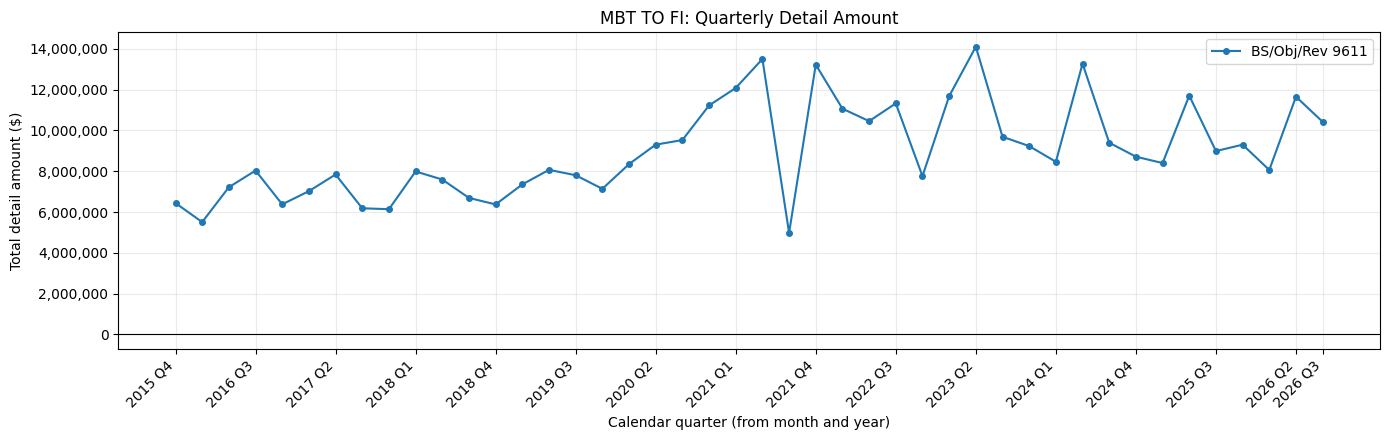

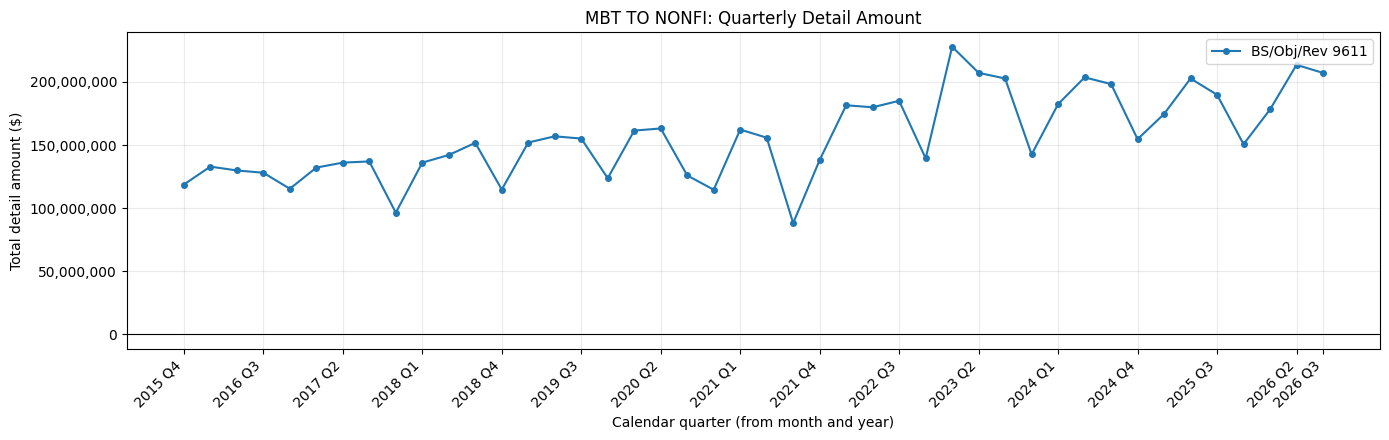

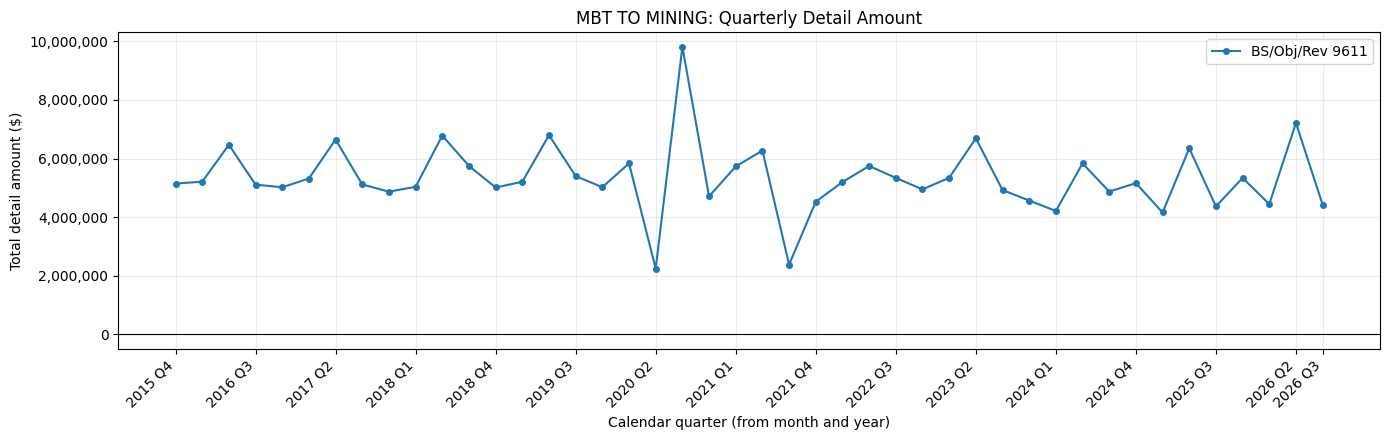

In [42]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Use the normalized Line #/Desc categories from the preceding cell.
quarterly_categories = ['MBT TO FI', 'MBT TO NONFI', 'MBT TO MINING']
quarterly_data = category_data.loc[category_data['category'].isin(quarterly_categories)].copy()
quarterly_data['Line #/Desc'] = quarterly_data['category']
quarter_dates = pd.to_datetime({
    'year': pd.to_numeric(quarterly_data['year'], errors='raise'),
    'month': pd.to_numeric(quarterly_data['month'], errors='raise'),
    'day': 1
}, errors='raise')
if quarter_dates.isna().any():
    raise ValueError('Some selected rows are missing month or year.')
quarterly_data['quarter'] = quarter_dates.dt.to_period('Q-DEC')
quarterly_totals = (
    quarterly_data.groupby(['Line #/Desc', 'BS/Obj/Rev', 'quarter'], as_index=False)
    ['detail_amount'].sum(min_count=1)
    .sort_values(['Line #/Desc', 'BS/Obj/Rev', 'quarter'])
)

for category in quarterly_categories:
    totals = quarterly_totals.loc[quarterly_totals['Line #/Desc'].eq(category)]
    if totals.empty:
        print(f'No quarterly data for {category}')
        continue
    quarters = pd.period_range(totals['quarter'].min(), totals['quarter'].max(), freq='Q-DEC')
    fig, ax = plt.subplots(figsize=(14, 4.5))
    # Keep accounting codes separate; absent quarters remain gaps, not zeroes.
    for code, group in totals.groupby('BS/Obj/Rev'):
        amounts = group.set_index('quarter')['detail_amount'].reindex(quarters)
        ax.plot(range(len(quarters)), amounts.to_numpy(dtype=float, na_value=float('nan')),
                marker='o', markersize=4, label=f'BS/Obj/Rev {code}')
    tick_step = max(1, (len(quarters) + 19) // 20)
    ticks = list(range(0, len(quarters), tick_step))
    if ticks[-1] != len(quarters) - 1:
        ticks.append(len(quarters) - 1)
    ax.set_xticks(ticks)
    ax.set_xticklabels([f'{quarters[i].year} Q{quarters[i].quarter}' for i in ticks],
                       rotation=45, ha='right')
    ax.set_title(f'{category}: Quarterly Detail Amount')
    ax.set_xlabel('Calendar quarter (from month and year)')
    ax.set_ylabel('Total detail amount ($)')
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value:,.0f}'))
    ax.axhline(0, color='black', linewidth=0.8)
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()
    plt.show()
